**Laboratorio de Métodos Cuantitativos Aplicados a la Gestión**

---

# **Integrales en el análisis económico: teoría y aplicaciones**

*Clase 16 · martes 13 de octubre — Marginalidad y totalidad + aplicación económica (integrales). Reúne en una sola clase las integrales indefinidas, las definidas y sus aplicaciones económicas.*

| Parte | Tema | Herramienta de Python |
|---|---|---|
| **1** | Integrar con Python: lo básico | `sp.integrate`, `scipy.integrate.quad`, `np.trapezoid` |
| **2** | De lo marginal a lo total | integral indefinida |
| **3** | Acumulados entre dos puntos | integral definida |
| **4** | Excedentes, impuestos y pérdida de peso muerto | integral definida |
| **5** | Cuando no hay fórmula: inflación, negocio, Gini y excedente con datos | regla del trapecio |
| **6** | ⭐ Ejercicios resueltos: excedente del consumidor e índice de Gini | todo junto |
| **7** | Ejercicios para practicar | — |

> 🎯 **La idea que une todo:** derivar es preguntar *"¿a qué velocidad cambia?"*; integrar es la
> pregunta inversa: *"si sé la velocidad, ¿cuánto se acumuló?"*. Y una integral definida
> **siempre** es un área bajo una curva.

**Complemento:** este notebook se acompaña con la presentación **Integrales.pdf**.

In [1]:
import numpy as np
import pandas as pd
import sympy as sp
import matplotlib.pyplot as plt
from scipy.integrate import quad, simpson

sp.init_printing()
pd.set_option("display.float_format", "{:,.2f}".format)
URL = "https://raw.githubusercontent.com/Datso653/Laboratorio-de-metodos-Cuantitativos-Aplicados-a-la-gestion/main/DF/"

# numpy cambió el nombre de la función en la versión 2.0. Esta línea funciona con las dos.
trapecio = getattr(np, "trapezoid", None) or np.trapz

---
# 🧰 Parte 1 — Integrar con Python: lo básico
---

En Python hay **tres caminos** para integrar, según qué información tengamos:

| Tengo... | Uso... | Devuelve |
|---|---|---|
| Una **fórmula** y quiero el resultado exacto | `sympy.integrate` | Una expresión simbólica (exacta) |
| Una **fórmula** y me alcanza con un número | `scipy.integrate.quad` | Un número (y su error estimado) |
| Solo **datos** (puntos sueltos) | `np.trapezoid` / `scipy.integrate.simpson` | Un número aproximado |

Vamos uno por uno.

## 1.1 Integral indefinida con `sp.integrate(f, x)`

Una *primitiva* o *integral indefinida* de $f(x)$ es cualquier función $F(x)$ tal que $F'(x) = f(x)$:

$$\int f(x)\, dx = F(x) + C$$

donde $C$ es la **constante de integración**. Derivar e integrar son operaciones inversas.

En `SymPy`, así como `sp.diff` deriva, `sp.integrate` integra. Se le pasa la función y la variable
de integración.

> ⚠️ `SymPy` **no agrega** la constante $C$: la tenemos que sumar nosotros cuando haga falta.

In [2]:
x = sp.symbols('x')

ejemplos = [3*x**2, sp.exp(x), 1/x, 4*x**3 - 2*x + 7]

for f in ejemplos:
    F = sp.integrate(f, x)
    print(f"∫ {str(f):<16} dx  =  {F}  + C")

∫ 3*x**2           dx  =  x**3  + C
∫ exp(x)           dx  =  exp(x)  + C
∫ 1/x              dx  =  log(x)  + C
∫ 4*x**3 - 2*x + 7 dx  =  x**4 - x**2 + 7*x  + C


In [3]:
# Comprobación: si derivamos la primitiva, volvemos a la función original
F = sp.integrate(3*x**2, x)
sp.diff(F, x)

## 1.2 La constante de integración

En economía la constante **casi nunca es cero**: en el costo total, por ejemplo, $C$ es el **costo fijo**
(lo que cuesta producir cero unidades). Para encontrarla usamos una **condición inicial**.

Sea $f(x) = 2x$ y supongamos que sabemos que $F(0) = 5$:
1. Integramos y sumamos un símbolo `C`.
2. Planteamos la condición con `sp.Eq` y despejamos con `sp.solve`.
3. Reemplazamos con `.subs`.

In [4]:
C = sp.symbols('C')

F3 = sp.integrate(2*x, x) + C                    # familia de primitivas: x² + C
condicion = sp.Eq(F3.subs(x, 0), 5)              # F(0) = 5
C_val = sp.solve(condicion, C)[0]                # despejamos C

F3 = F3.subs(C, C_val)
print("C =", C_val)
F3

C = 5


## 1.3 Integral definida con `sp.integrate(f, (x, a, b))`

La *integral definida* de $f(x)$ entre $a$ y $b$ es el **acumulado neto** de $f$ en ese intervalo;
geométricamente, el **área bajo la curva**. Se calcula con la **Regla de Barrow** (Teorema Fundamental del Cálculo):

$$\int_a^b f(x)\,dx = F(b) - F(a)$$

En `SymPy` solo cambia el segundo argumento: en vez de `x`, la tupla `(x, a, b)`.

Ejemplo: $\displaystyle\int_0^3 x^2\,dx = \left.\frac{x^3}{3}\right|_0^3 = \frac{27}{3} - 0 = 9$

In [5]:
f1 = x**2
a, b = 0, 3

area = sp.integrate(f1, (x, a, b))
print("Integral definida entre 0 y 3:", area)

# Lo mismo con Barrow, a mano:
F1 = sp.integrate(f1, x)
print("F(3) - F(0)              :", F1.subs(x, b) - F1.subs(x, a))

Integral definida entre 0 y 3: 9
F(3) - F(0)              : 9


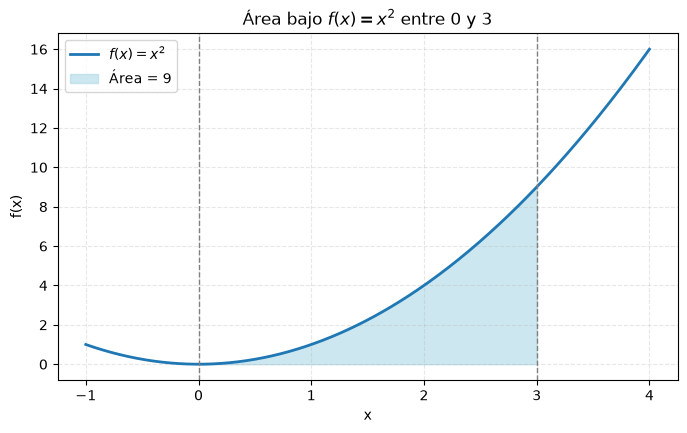

In [6]:
f1_num = sp.lambdify(x, f1)           # lambdify: convierte la expresión de SymPy en función de numpy

x_full = np.linspace(-1, 4, 400)
x_fill = np.linspace(a, b, 300)

plt.figure(figsize=(8, 4.5))
plt.plot(x_full, f1_num(x_full), linewidth=2, label=r'$f(x)=x^2$')
plt.fill_between(x_fill, f1_num(x_fill), color='lightblue', alpha=0.6, label=f'Área = {area}')
plt.axvline(a, color='gray', linestyle='--', linewidth=1)
plt.axvline(b, color='gray', linestyle='--', linewidth=1)
plt.title('Área bajo $f(x)=x^2$ entre 0 y 3')
plt.xlabel('x'); plt.ylabel('f(x)')
plt.legend(); plt.grid(True, linestyle='--', alpha=0.3)
plt.show()

## 1.4 ¿Qué está calculando realmente? Sumas de Riemann

Integrar es **sumar rectángulos** de base cada vez más fina. Con $n$ rectángulos de ancho
$\Delta x = \frac{b-a}{n}$, la suma de sus áreas se acerca a la integral a medida que $n$ crece.

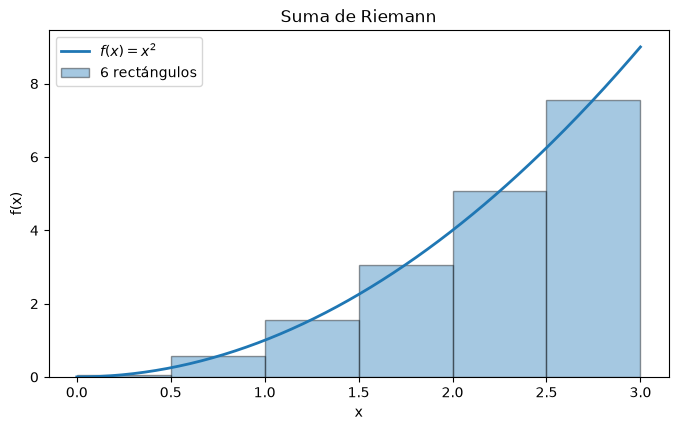

     n |  Suma de Riemann |     Error
--------------------------------------
     6 |         8.937500 | -0.062500
    20 |         8.994375 | -0.005625
   100 |         8.999775 | -0.000225
  1000 |         8.999998 | -0.000002


In [7]:
n = 6
bordes = np.linspace(a, b, n + 1)
medios = (bordes[:-1] + bordes[1:]) / 2          # tomamos la altura en el punto medio
dx = (b - a) / n

plt.figure(figsize=(8, 4.5))
plt.plot(x_fill, f1_num(x_fill), linewidth=2, label=r'$f(x)=x^2$')
plt.bar(bordes[:-1], f1_num(medios), width=dx, align='edge', alpha=0.4, edgecolor='k',
        label=f'{n} rectángulos')
plt.title('Suma de Riemann')
plt.xlabel('x'); plt.ylabel('f(x)'); plt.legend()
plt.show()

print(f"{'n':>6} | {'Suma de Riemann':>16} | {'Error':>9}")
print("-" * 38)
for n in [6, 20, 100, 1000]:
    bordes = np.linspace(a, b, n + 1)
    medios = (bordes[:-1] + bordes[1:]) / 2
    suma = np.sum(f1_num(medios) * (b - a) / n)
    print(f"{n:>6} | {suma:>16.6f} | {suma - 9:>9.6f}")

## 1.5 Integración numérica de una fórmula: `scipy.integrate.quad`

A veces la fórmula existe pero **no tiene primitiva elemental** (o no nos interesa la expresión, solo el número).
El caso clásico es la campana de Gauss, $e^{-x^2}$: `SymPy` responde con una función especial (`erf`),
mientras que `quad` devuelve directamente **el número y una estimación del error**.

`quad(funcion, a, b)` necesita una función de Python/numpy, no una expresión de SymPy:
por eso usamos `sp.lambdify` para pasar de una a otra.

In [8]:
g = sp.exp(-x**2)

exacta = sp.integrate(g, (x, 0, 2))
print("SymPy (exacta)  :", exacta, "=", float(exacta))

valor, error = quad(sp.lambdify(x, g), 0, 2)
print(f"SciPy quad      : {valor:.10f}   (error estimado: {error:.1e})")

SymPy (exacta)  : sqrt(pi)*erf(2)/2 = 0.8820813907624216
SciPy quad      : 0.8820813908   (error estimado: 9.8e-15)


## 1.6 Cuando solo hay datos: la regla del trapecio

En el trabajo real muchas veces **no hay fórmula, hay una planilla**. Si solo tenemos puntos,
los unimos con rectas y sumamos el área de los **trapecios** que quedan:

```
   y                                  Área de cada trapecio:
   │        ●───────●
   │       ╱│░░░░░░░│╲                  (base_menor + base_mayor)
   │  ●───╱ │░░░░░░░│ ╲───●             ──────────────────────── × ancho
   │ ╱│░░░░░│░░░░░░░│░░░░░│╲                       2
   └──┴─────┴───────┴─────┴──── x       y sumamos todos.
```

`trapecio(y, x)` hace exactamente eso. `simpson(y, x=x)` es una variante que usa **parábolas**
en vez de rectas y suele equivocarse menos. Comparamos contra el valor exacto de $\int_0^3 x^2 dx = 9$:

In [9]:
print(f"{'Puntos':>7} | {'Trapecio':>10} | {'Error':>8} | {'Simpson':>10} | {'Error':>8}")
print("-" * 54)
for n in [5, 11, 51, 501]:
    xs = np.linspace(0, 3, n)
    ys = xs ** 2
    t, s = trapecio(ys, xs), simpson(ys, x=xs)
    print(f"{n:>7} | {t:>10.5f} | {t - 9:>8.5f} | {s:>10.5f} | {s - 9:>8.5f}")

 Puntos |   Trapecio |    Error |    Simpson |    Error
------------------------------------------------------
      5 |    9.28125 |  0.28125 |    9.00000 |  0.00000
     11 |    9.04500 |  0.04500 |    9.00000 |  0.00000
     51 |    9.00180 |  0.00180 |    9.00000 | -0.00000
    501 |    9.00002 |  0.00002 |    9.00000 |  0.00000


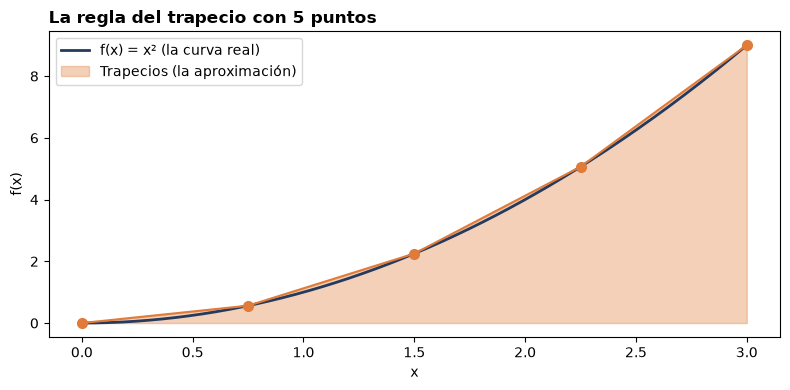

In [10]:
x_pocos = np.linspace(0, 3, 5)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(x_fill, x_fill**2, color="#243b5e", linewidth=2, label="f(x) = x² (la curva real)")
ax.fill_between(x_pocos, x_pocos**2, alpha=0.35, color="#e07b39", label="Trapecios (la aproximación)")
ax.plot(x_pocos, x_pocos**2, "o-", color="#e07b39", markersize=7)
ax.set_title("La regla del trapecio con 5 puntos", loc="left", fontweight="bold")
ax.set_xlabel("x"); ax.set_ylabel("f(x)"); ax.legend()
plt.tight_layout(); plt.show()

Los trapecios **sobreestiman** el área porque la curva es convexa y las rectas pasan por arriba
(por eso el error es positivo). Simpson es exacto acá porque $x^2$ *es* una parábola.

> 📌 El error de la integración numérica **siempre existe**, pero se achica rápido.
> Para tomar una decisión de gestión, un error del 0,01 % no cambia nada.

---
# 📗 Parte 2 — De lo marginal a lo total (integral indefinida)
---

Si conocemos una función **marginal** (costo marginal, ingreso marginal, producto marginal),
integrando recuperamos la función **total**. La constante de integración tiene sentido económico:

| Marginal | Total | Constante de integración |
|---|---|---|
| $CMg(q)$ | $C(q) = \int CMg\, dq + CF$ | Costo fijo: $C(0) = CF$ |
| $IMg(q)$ | $I(q) = \int IMg\, dq$ | $I(0) = 0$ (sin ventas no hay ingreso) |
| $PMg(L)$ | $P(L) = \int PMg\, dL$ | $P(0) = 0$ (sin trabajo no hay producto) |

## 2.1 Costo marginal → costo total

Sea un costo marginal lineal $CMg = \alpha q + \beta$ con $\alpha, \beta > 0$. Entonces

$$C(q) = \int (\alpha q + \beta)\, dq = \frac{\alpha}{2} q^2 + \beta q + CF$$

Y si el costo marginal es convexo, $CMg = \alpha q + \gamma q^2 + \beta$:

$$C(q) = \frac{\alpha}{2} q^2 + \frac{\gamma}{3} q^3 + \beta q + CF$$

In [11]:
q = sp.symbols('q', nonnegative=True)
alpha, beta, gamma, CF = sp.symbols('alpha beta gamma CF', positive=True)

CMg_lin = alpha*q + beta
CMg_cvx = alpha*q + gamma*q**2 + beta

C_lin = sp.integrate(CMg_lin, q) + CF
C_cvx = sp.integrate(CMg_cvx, q) + CF

display(C_lin, C_cvx)

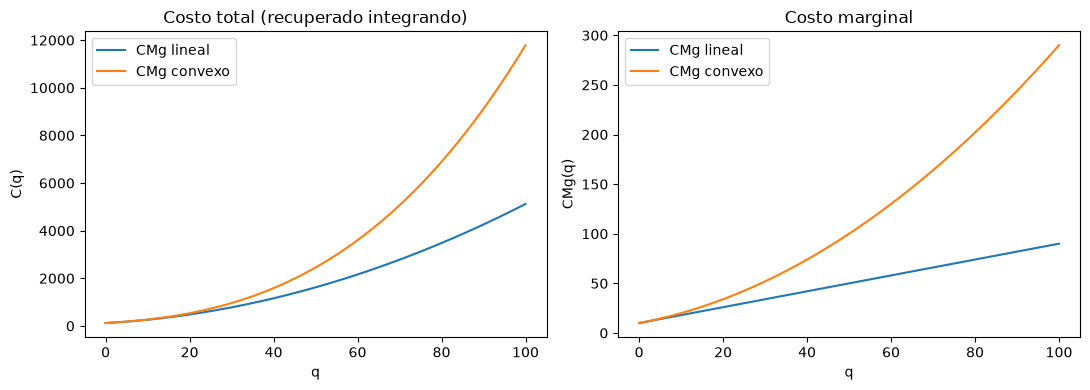

In [12]:
valores = {alpha: 0.8, beta: 10, gamma: 0.02, CF: 120}
q_grid = np.linspace(0, 100, 300)

fig, axs = plt.subplots(1, 2, figsize=(11, 4))
for CMg_i, C_i, nombre in [(CMg_lin, C_lin, "lineal"), (CMg_cvx, C_cvx, "convexo")]:
    axs[0].plot(q_grid, sp.lambdify(q, C_i.subs(valores))(q_grid), label=f"CMg {nombre}")
    axs[1].plot(q_grid, sp.lambdify(q, CMg_i.subs(valores))(q_grid), label=f"CMg {nombre}")

axs[0].set_title("Costo total (recuperado integrando)"); axs[0].set_xlabel("q"); axs[0].set_ylabel("C(q)")
axs[1].set_title("Costo marginal"); axs[1].set_xlabel("q"); axs[1].set_ylabel("CMg(q)")
axs[0].legend(); axs[1].legend()
plt.tight_layout(); plt.show()

Todas las curvas de costo total arrancan en $C(0) = 120$: **el costo fijo es la constante de integración**.

## 2.2 Ingreso marginal → ingreso total, y el equilibrio del monopolio

Con demanda lineal $p(q) = a - bq$, el ingreso marginal es $IMg(q) = a - 2bq$.
Hagamos el camino inverso: partimos de $IMg$ e integramos. No sumamos constante porque $I(0) = 0$.

In [13]:
a, b = sp.symbols('a b', positive=True)

IMg = a - 2*b*q
I = sp.integrate(IMg, q)

print("I(q) =", I)
print("¿Coincide con p(q)·q?", sp.simplify(I - (a - b*q)*q) == 0)

I(q) = a*q - b*q**2
¿Coincide con p(q)·q? True


Ahora un monopolio con $p(q) = 80 - 0{,}2q$, $CMg = 0{,}8q + 10$ y costo fijo de \$120.
Recuperamos $I(q)$ y $C(q)$ integrando, y el óptimo cumple $IMg(q^*) = CMg(q^*)$.

In [14]:
r = sp.Rational                                  # usamos fracciones exactas para resultados limpios

p_q  = 80 - r(1, 5)*q
IMg  = 80 - r(2, 5)*q
CMg  = r(4, 5)*q + 10

I = sp.integrate(IMg, q)                         # I(0) = 0
C = sp.integrate(CMg, q) + 120                   # C(0) = 120 (costo fijo)
B = I - C

q_opt = sp.solve(sp.Eq(IMg, CMg), q)[0]
p_opt = p_q.subs(q, q_opt)
B_opt = B.subs(q, q_opt)

print(f"I(q) = {I}")
print(f"C(q) = {C}")
print(f"\nq* = {q_opt} ≈ {float(q_opt):.2f}")
print(f"p* = {p_opt} ≈ {float(p_opt):.2f}")
print(f"B* = {B_opt} ≈ {float(B_opt):,.2f}")

I(q) = -q**2/5 + 80*q
C(q) = 2*q**2/5 + 10*q + 120

q* = 175/3 ≈ 58.33
p* = 205/3 ≈ 68.33
B* = 5765/3 ≈ 1,921.67


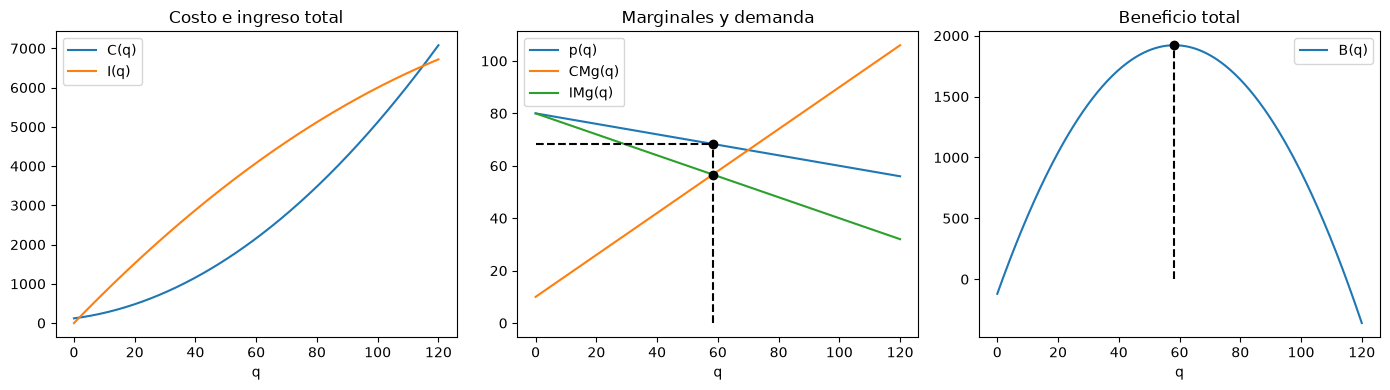

In [15]:
q_grid = np.linspace(0, 120, 300)
num = lambda expr: sp.lambdify(q, expr)(q_grid) * np.ones_like(q_grid)
qo, po, Bo = float(q_opt), float(p_opt), float(B_opt)

fig, axs = plt.subplots(1, 3, figsize=(14, 4))

axs[0].plot(q_grid, num(C), label="C(q)")
axs[0].plot(q_grid, num(I), label="I(q)")
axs[0].set_title("Costo e ingreso total"); axs[0].legend()

axs[1].plot(q_grid, num(p_q), label="p(q)")
axs[1].plot(q_grid, num(CMg), label="CMg(q)")
axs[1].plot(q_grid, num(IMg), label="IMg(q)")
axs[1].scatter([qo, qo], [float(CMg.subs(q, q_opt)), po], c="black", zorder=3)
axs[1].hlines(po, 0, qo, color="black", linestyle="--")
axs[1].vlines(qo, 0, po, color="black", linestyle="--")
axs[1].set_title("Marginales y demanda"); axs[1].legend()

axs[2].plot(q_grid, num(B), label="B(q)")
axs[2].scatter(qo, Bo, c="black", zorder=3)
axs[2].vlines(qo, 0, Bo, color="black", linestyle="--")
axs[2].set_title("Beneficio total"); axs[2].legend()

for ax in axs: ax.set_xlabel("q")
plt.tight_layout(); plt.show()

## 2.3 Producto marginal → producto total

Con producto marginal de rendimientos decrecientes $PMg(L) = \gamma L^{\delta}$, $0 < \delta < 1$,
y $P(0) = 0$:

$$P(L) = \int \gamma L^{\delta}\, dL = \frac{\gamma}{\delta + 1} L^{\delta + 1}$$

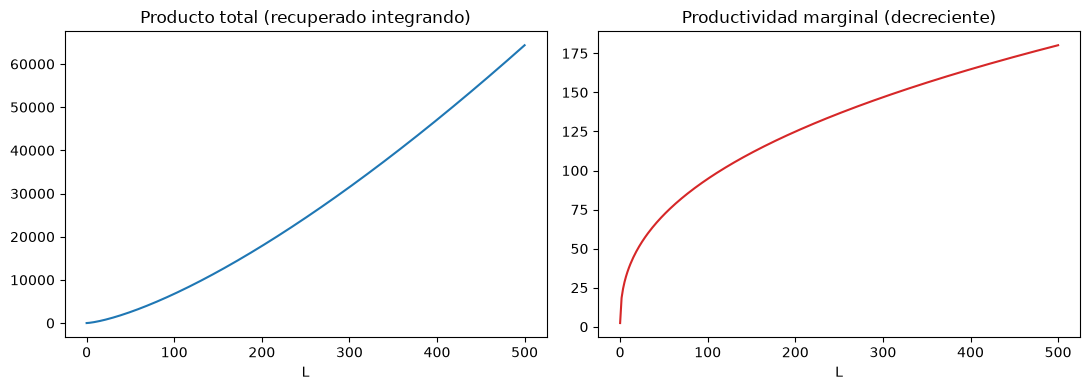

In [16]:
L, gam, delta = sp.symbols('L gamma delta', positive=True)

PMg = gam * L**delta
P = sp.simplify(sp.integrate(PMg, L))
display(P)

vals = {gam: 15, delta: 0.4}
L_grid = np.linspace(0.01, 500, 300)

fig, axs = plt.subplots(1, 2, figsize=(11, 4))
axs[0].plot(L_grid, sp.lambdify(L, P.subs(vals))(L_grid))
axs[0].set_title("Producto total (recuperado integrando)"); axs[0].set_xlabel("L")
axs[1].plot(L_grid, sp.lambdify(L, PMg.subs(vals))(L_grid), color="tab:red")
axs[1].set_title("Productividad marginal (decreciente)"); axs[1].set_xlabel("L")
plt.tight_layout(); plt.show()

---
# 📘 Parte 3 — Acumulados entre dos puntos (integral definida)
---

En gestión la pregunta suele ser *"¿cuánto se acumuló **entre** A y B?"*:
*¿cuánto ingreso agregan las unidades 10 a 20?, ¿cuánto cuesta pasar de producir 10 a producir 20?*

Hay dos caminos equivalentes (Barrow):

$$\underbrace{I(20) - I(10)}_{\text{restar totales}} \;=\; \underbrace{\int_{10}^{20} IMg(q)\, dq}_{\text{área bajo la marginal}}$$

## 3.1 Ingreso acumulado
Demanda inversa $P(q) = 80 - 1{,}5q$, ingreso total $I(q) = P(q)\cdot q$.

In [17]:
q = sp.symbols('q', nonnegative=True)

P_q = 80 - sp.Rational(3, 2)*q
I = P_q * q
IMg = sp.diff(I, q)

print("Restando totales  I(20) - I(10)  =", I.subs(q, 20) - I.subs(q, 10))
print("Integrando ∫ IMg dq entre 10 y 20 =", sp.integrate(IMg, (q, 10, 20)))

Restando totales  I(20) - I(10)  = 350
Integrando ∫ IMg dq entre 10 y 20 = 350


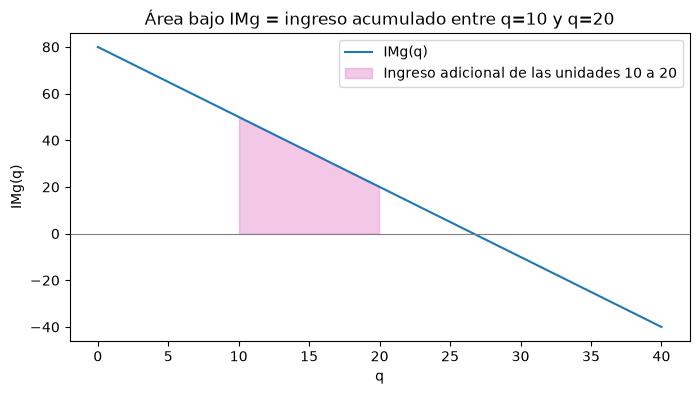

In [18]:
q_grid = np.linspace(0, 40, 400)
IMg_num = sp.lambdify(q, IMg)(q_grid)

plt.figure(figsize=(8, 4))
plt.plot(q_grid, IMg_num, label='IMg(q)')
plt.fill_between(q_grid, IMg_num, 0, where=(q_grid >= 10) & (q_grid <= 20),
                 color="tab:pink", alpha=0.4, label="Ingreso adicional de las unidades 10 a 20")
plt.axhline(0, color="gray", linewidth=0.8)
plt.title('Área bajo IMg = ingreso acumulado entre q=10 y q=20')
plt.xlabel('q'); plt.ylabel('IMg(q)'); plt.legend()
plt.show()

> 💡 $I(\bar q)$ **ya acumula** el ingreso de todas las unidades desde 0 hasta $\bar q$.
> Integrar $I(q)$ sería "acumular un acumulado" y no tiene interpretación económica.
> Lo que se integra es **la marginal**.

## 3.2 Costo acumulado

Con $CMg(q) = \frac{q^2}{3} + 2q$ y costo fijo $C(0) = 25$, ¿cuánto cuesta pasar de 10 a 20 unidades?
El costo fijo **se cancela** en la resta: lo que se acumula es solo **costo variable**.

In [19]:
F = sp.symbols('F')

CMg = q**2/3 + 2*q
C = sp.integrate(CMg, q) + F
C = C.subs(F, sp.solve(sp.Eq(C.subs(q, 0), 25), F)[0])

print("C(q) =", C)
print("\nC(20) - C(10)        =", C.subs(q, 20) - C.subs(q, 10), "≈", float(C.subs(q, 20) - C.subs(q, 10)))
print("∫ CMg dq de 10 a 20  =", sp.integrate(CMg, (q, 10, 20)))

C(q) = q**3/9 + q**2 + 25

C(20) - C(10)        = 9700/9 ≈ 1077.7777777777778
∫ CMg dq de 10 a 20  = 9700/9


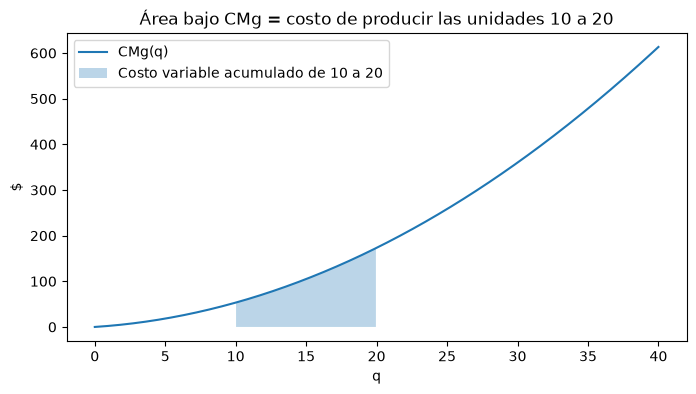

In [20]:
CMg_num = sp.lambdify(q, CMg)(q_grid)

plt.figure(figsize=(8, 4))
plt.plot(q_grid, CMg_num, label='CMg(q)')
plt.fill_between(q_grid, CMg_num, where=(q_grid >= 10) & (q_grid <= 20),
                 alpha=0.3, label='Costo variable acumulado de 10 a 20')
plt.title('Área bajo CMg = costo de producir las unidades 10 a 20')
plt.xlabel('q'); plt.ylabel('$'); plt.legend()
plt.show()

---
# 🏛️ Parte 4 — Excedentes, impuestos y pérdida de peso muerto
---

Los excedentes miden el **bienestar** que genera un mercado:

- **Excedente del Consumidor (EC):** lo que ganan los consumidores por pagar menos de lo que estaban dispuestos a pagar.
- **Excedente del Productor (EP):** lo que ganan los productores por vender más caro que el mínimo que aceptarían (su costo marginal).

Antes los calculábamos como triángulos. Con integrales funcionan **con cualquier forma de curva**.
Usando las demandas y ofertas **inversas** $P_d(q)$ y $P_s(q)$:

$$EC = \int_0^{q^*} \big[P_d(q) - p^*\big]\, dq \qquad\qquad EP = \int_0^{q^*} \big[p^* - P_s(q)\big]\, dq$$

## 4.1 Excedentes en equilibrio

Demanda $Q_d(p) = 120 - 3p$ y oferta $Q_s(p) = -20 + 2p$. Despejando $p$:
$P_d(q) = \frac{120 - q}{3}$ y $P_s(q) = \frac{q + 20}{2}$.

In [21]:
q = sp.symbols('q', nonnegative=True)

P_d = (120 - q) / 3        # disposición máxima a pagar por la unidad q
P_s = (q + 20) / 2         # precio mínimo al que se ofrece la unidad q

q_eq = sp.solve(sp.Eq(P_d, P_s), q)[0]
p_eq = P_d.subs(q, q_eq)

EC = sp.integrate(P_d - p_eq, (q, 0, q_eq))
EP = sp.integrate(p_eq - P_s, (q, 0, q_eq))

print(f"Equilibrio: q* = {q_eq}, p* = {p_eq}")
print(f"EC = {EC}")
print(f"EP = {EP}")
print(f"Bienestar total = {EC + EP}")

Equilibrio: q* = 36, p* = 28
EC = 216
EP = 324
Bienestar total = 540


Visualmente, el EC es la suma de "rectángulos" entre la demanda y el precio, uno por cada unidad
comprada. Cada rectángulo es lo que *ese* consumidor estaba dispuesto a pagar de más.

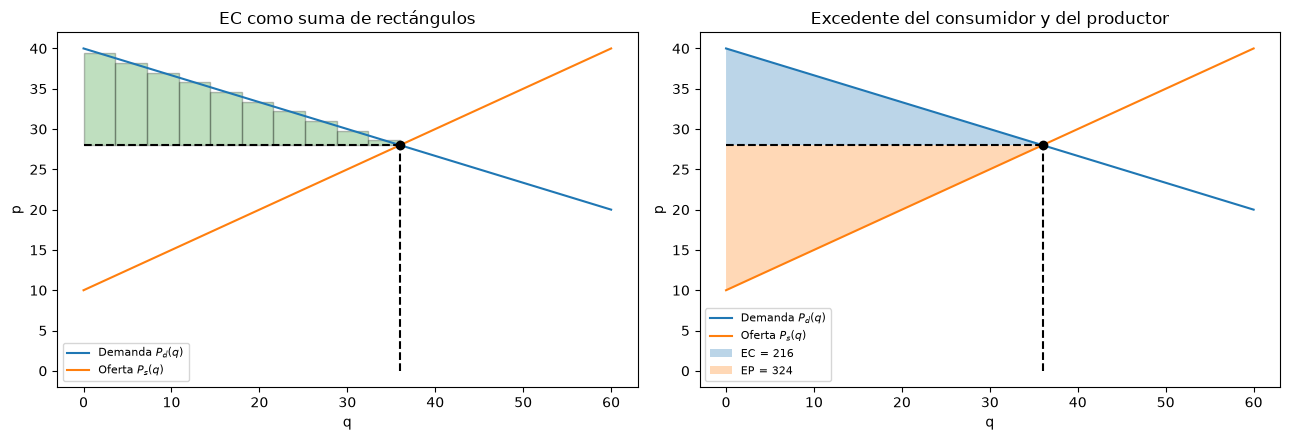

In [22]:
q_grid = np.linspace(0, 60, 500)
Pd_num = sp.lambdify(q, P_d)(q_grid)
Ps_num = sp.lambdify(q, P_s)(q_grid)
qe, pe = float(q_eq), float(p_eq)

fig, axs = plt.subplots(1, 2, figsize=(13, 4.5))

# Izquierda: rectángulos de Riemann del EC
n = 10
bordes = np.linspace(0, qe, n + 1)
medios = (bordes[:-1] + bordes[1:]) / 2
axs[0].plot(q_grid, Pd_num, label='Demanda $P_d(q)$')
axs[0].plot(q_grid, Ps_num, label='Oferta $P_s(q)$')
axs[0].bar(bordes[:-1], sp.lambdify(q, P_d)(medios) - pe, width=qe / n, bottom=pe,
           align='edge', color="green", alpha=0.25, edgecolor='k')
axs[0].set_title('EC como suma de rectángulos')

# Derecha: EC y EP como áreas
axs[1].plot(q_grid, Pd_num, label='Demanda $P_d(q)$')
axs[1].plot(q_grid, Ps_num, label='Oferta $P_s(q)$')
axs[1].fill_between(q_grid, Pd_num, pe, where=q_grid <= qe, alpha=0.3, label=f'EC = {EC}')
axs[1].fill_between(q_grid, pe, Ps_num, where=q_grid <= qe, alpha=0.3, label=f'EP = {EP}')
axs[1].set_title('Excedente del consumidor y del productor')

for ax in axs:
    ax.hlines(pe, 0, qe, linestyles="--", color="black")
    ax.vlines(qe, 0, pe, linestyles="--", color="black")
    ax.scatter([qe], [pe], c="black", zorder=3)
    ax.set_xlabel('q'); ax.set_ylabel('p'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 4.2 Un impuesto por unidad y la pérdida de peso muerto

Supongamos un impuesto de $t = \$5$ **por unidad** que pagan los productores. Para vender la unidad $q$
ahora necesitan cobrar $t$ más: la oferta se desplaza a $P_s^t(q) = P_s(q) + t$.

- El nuevo equilibrio $q^t$ sale de $P_d(q) = P_s^t(q)$.
- El consumidor paga $p_c = P_d(q^t)$; el productor se queda con $p_p = p_c - t$.
- El Estado recauda $t \cdot q^t$.

La **pérdida de peso muerto (DWL)** es el bienestar que *nadie* se queda: las unidades entre $q^t$ y $q^*$
que valían la pena producir y ya no se producen:

$$DWL = \int_{q^t}^{q^*} \big[P_d(q) - P_s(q)\big]\, dq$$

In [23]:
t = 5
P_s_t = P_s + t

q_t = sp.solve(sp.Eq(P_d, P_s_t), q)[0]
p_c = P_d.subs(q, q_t)                 # precio que paga el consumidor
p_p = p_c - t                          # precio que recibe el productor

EC_t = sp.integrate(P_d - p_c, (q, 0, q_t))
EP_t = sp.integrate(p_p - P_s, (q, 0, q_t))
recaudacion = t * q_t
DWL = sp.integrate(P_d - P_s, (q, q_t, q_eq))

tabla = pd.DataFrame({
    "Sin impuesto": [EC, EP, 0, EC + EP],
    "Con impuesto": [EC_t, EP_t, recaudacion, EC_t + EP_t + recaudacion],
}, index=["Excedente consumidor", "Excedente productor", "Recaudación", "Bienestar total"]).astype(float)
tabla["Variación"] = tabla["Con impuesto"] - tabla["Sin impuesto"]

print(f"Nuevo equilibrio: q = {q_t}, paga el consumidor ${p_c}, recibe el productor ${p_p}")
print(f"Pérdida de peso muerto (integral): {DWL}\n")
tabla

Nuevo equilibrio: q = 30, paga el consumidor $30, recibe el productor $25
Pérdida de peso muerto (integral): 15



,Sin impuesto,Con impuesto,Variación
Excedente consumidor,216.00,150.00,-66.00
Excedente productor,324.00,225.00,-99.00
Recaudación,0.00,150.00,150.00
Bienestar total,540.00,525.00,-15.00


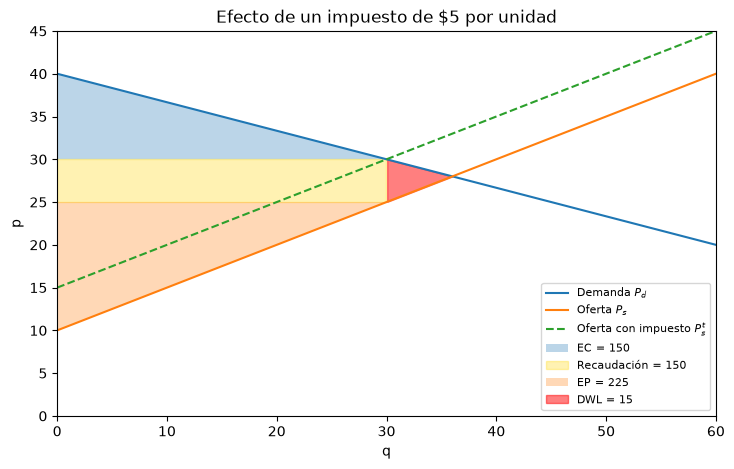

In [24]:
qt, pc, pp = float(q_t), float(p_c), float(p_p)

plt.figure(figsize=(8.5, 5))
plt.plot(q_grid, Pd_num, label='Demanda $P_d$')
plt.plot(q_grid, Ps_num, label='Oferta $P_s$')
plt.plot(q_grid, sp.lambdify(q, P_s_t)(q_grid), '--', label='Oferta con impuesto $P_s^t$')

plt.fill_between(q_grid, Pd_num, pc, where=q_grid <= qt, alpha=0.3, label=f'EC = {float(EC_t):.0f}')
plt.fill_between(q_grid, pc, pp, where=q_grid <= qt, alpha=0.3, color="gold", label=f'Recaudación = {float(recaudacion):.0f}')
plt.fill_between(q_grid, pp, Ps_num, where=q_grid <= qt, alpha=0.3, label=f'EP = {float(EP_t):.0f}')
plt.fill_between(q_grid, Pd_num, Ps_num, where=(q_grid >= qt) & (q_grid <= qe),
                 color="red", alpha=0.5, label=f'DWL = {float(DWL):.0f}')

plt.xlim(0, 60); plt.ylim(0, 45)
plt.title('Efecto de un impuesto de $5 por unidad')
plt.xlabel('q'); plt.ylabel('p'); plt.legend(fontsize=8)
plt.show()

El bienestar total cae exactamente en el **triángulo rojo**: el impuesto transfiere excedente al
Estado (amarillo), pero además **destruye** bienestar al eliminar transacciones que convenían a ambas partes.

---
# 📊 Parte 5 — Cuando no hay fórmula: aplicaciones con datos
---

Nadie te va a dar la fórmula de la inflación argentina ni la de las ventas de tu empresa. Te van a dar
**una planilla**. Y aun así hay que calcular acumulados, áreas y excedentes.

> **La idea:** si tenés la fórmula, la integral se calcula exacta. Si solo tenés puntos, se **aproxima**
> con trapecios. Para decidir, la aproximación alcanza.

## 5.1 Inflación acumulada

El INDEC publica la inflación **mensual**: es una función *marginal* (la velocidad a la que suben los precios).
Lo que importa es la inflación **acumulada**: la función *total*.

In [25]:
# Inflación mensual de 2023 en Argentina, en % (fuente: INDEC, IPC Nacional)
meses = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]
inflacion_mensual = np.array([6.0, 6.6, 7.7, 8.4, 7.8, 6.0, 6.3, 12.4, 12.7, 8.3, 12.8, 25.5])

ipc = pd.DataFrame({"mes": meses, "inflacion_mensual": inflacion_mensual})
ipc.T

,0,1,2,3,4,5,6,7,8,9,10,11
mes,Ene,Feb,Mar,Abr,May,Jun,Jul,Ago,Sep,Oct,Nov,Dic
inflacion_mensual,6.00,6.60,7.70,8.40,7.80,6.00,6.30,12.40,12.70,8.30,12.80,25.50


### ⚠️ La trampa: la inflación NO se suma

Cada mes los precios suben sobre el nivel **ya aumentado** del mes anterior (interés compuesto).
Lo correcto es multiplicar los factores:

$$\text{acumulada} = \left[\prod_{i=1}^{12}\left(1 + \frac{\pi_i}{100}\right) - 1\right] \times 100$$

In [26]:
suma_ingenua = inflacion_mensual.sum()

factores = 1 + inflacion_mensual / 100        # cada mes multiplica por su factor
acumulada = (np.prod(factores) - 1) * 100     # prod: multiplica todos los elementos

print(f"Sumando (MAL)      : {suma_ingenua:>6.1f} %")
print(f"Componiendo (BIEN) : {acumulada:>6.1f} %")
print(f"\nLa diferencia es de {acumulada - suma_ingenua:.0f} puntos porcentuales.")

Sumando (MAL)      :  120.5 %
Componiendo (BIEN) :  211.2 %

La diferencia es de 91 puntos porcentuales.


### ¿Y dónde está la integral?

En los **logaritmos**: el producto se convierte en suma, y la suma de tasas instantáneas es el área
bajo la curva de inflación:

$$\ln\left(\frac{P_{final}}{P_{inicial}}\right) = \sum_i \ln(1 + \pi_i) \;\approx\; \int_0^{12} \pi(t)\, dt$$

La inflación acumulada **es el área bajo la curva de la inflación mensual, medida en logaritmos**.

Área en logaritmos         : 1.1353
exp(área) - 1, en %        : 211.2 %   ← coincide con la acumulada


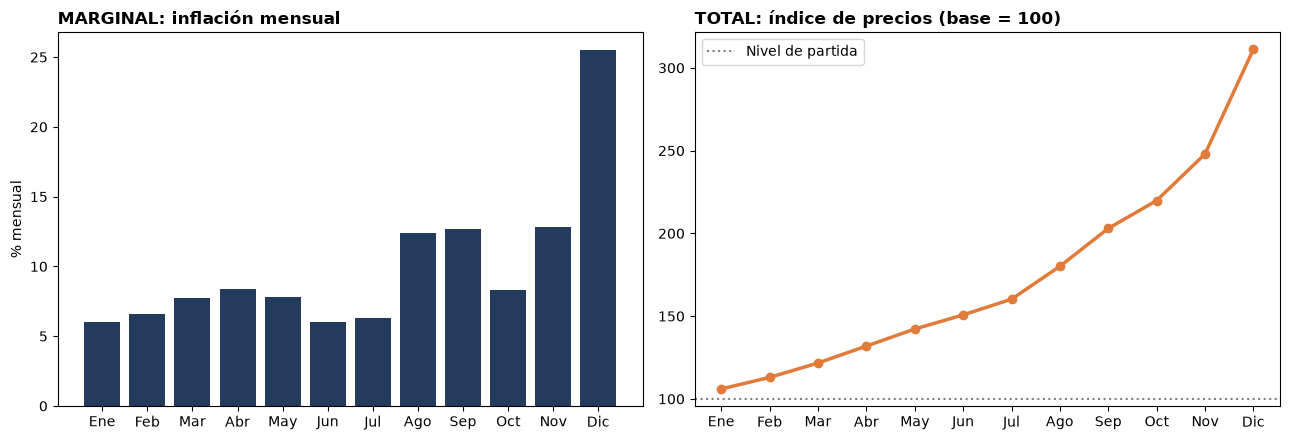

In [27]:
area_log = np.sum(np.log(factores))          # "área" en logaritmos
print(f"Área en logaritmos         : {area_log:.4f}")
print(f"exp(área) - 1, en %        : {(np.exp(area_log) - 1) * 100:.1f} %   ← coincide con la acumulada")

ipc["indice"] = 100 * np.cumprod(factores)   # cumprod: producto acumulado mes a mes
ipc["acumulada_%"] = ipc["indice"] - 100

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
ax1.bar(meses, inflacion_mensual, color="#243b5e")
ax1.set_title("MARGINAL: inflación mensual", loc="left", fontweight="bold"); ax1.set_ylabel("% mensual")
ax2.plot(meses, ipc["indice"], marker="o", color="#e07b39", linewidth=2.5)
ax2.axhline(100, color="gray", linestyle=":", label="Nivel de partida")
ax2.set_title("TOTAL: índice de precios (base = 100)", loc="left", fontweight="bold"); ax2.legend()
plt.tight_layout(); plt.show()

**Este par de gráficos resume todo el tema:** a la izquierda la derivada (la velocidad), a la derecha la
primitiva (el acumulado). Integrar es pasar del gráfico de la izquierda al de la derecha.

## 5.2 El ingreso acumulado de un negocio

Datos de 12 semanas de un supermercado. Tenemos el ingreso de cada semana y queremos el acumulado.

In [28]:
sup = pd.read_csv(URL + "datos_supermercado_simulados.csv")

sup["ingreso"] = (sup["cant_alimentos"] * sup["precio_alimentos"] +
                  sup["cant_bebidas"]   * sup["precio_bebidas"] +
                  sup["cant_limpieza"]  * sup["precio_limpieza"])
sup["margen"] = sup["ingreso"] - sup["costos_operativos"]
sup["margen_acumulado"] = sup["margen"].cumsum()     # cumsum: suma acumulada

suma_simple = sup["ingreso"].sum()
area_trapecio = trapecio(sup["ingreso"].values, sup["semana"].values)
print(f"Suma de las 12 semanas      : $ {suma_simple:>12,.0f}")
print(f"Área por regla del trapecio : $ {area_trapecio:>12,.0f}")

sup[["semana", "ingreso", "costos_operativos", "margen", "margen_acumulado"]]

Suma de las 12 semanas      : $    3,830,348
Área por regla del trapecio : $    3,502,774


,semana,ingreso,costos_operativos,margen,margen_acumulado
0,1,342862,33161,309701,309701
1,2,330082,37297,292785,602486
2,3,300195,34981,265214,867700
3,4,323358,33995,289363,1157063
4,5,312588,39413,273175,1430238
5,6,332645,37911,294734,1724972
6,7,320137,36342,283795,2008767
7,8,325539,37551,287988,2296755
8,9,289562,40629,248933,2545688
9,10,302980,36798,266182,2811870


### ¿Suma o integral? La pregunta clave

| Método | Supone que... | Sirve para |
|---|---|---|
| **Suma** (`.sum()`) | Cada dato es un **total ya cerrado** del período | Ingresos, unidades vendidas, gastos |
| **Trapecio** | Los datos son **mediciones instantáneas** de algo continuo | Tasas de producción, caudales, velocidades |

Acá el ingreso semanal ya es un total cerrado → **la suma es la correcta**. El trapecio le "corta" media
semana en cada extremo.

> 🎯 Siempre preguntate: ¿mi dato es un *flujo ya acumulado* (se suma) o una *medición puntual de una
> velocidad* (se integra)?

## 5.3 Desigualdad: curva de Lorenz y coeficiente de Gini

Ordenamos a la población de menor a mayor ingreso y preguntamos *"¿qué porcentaje del ingreso total se
lleva el X % más pobre?"*. Esa es la **curva de Lorenz** $L(p)$.

- Con igualdad perfecta, el 20 % más pobre se lleva el 20 % del ingreso: la curva es la **diagonal** $L(p) = p$.
- En la realidad la curva se hunde por debajo de la diagonal. **Cuánto se hunde es la desigualdad.**

$$G = \frac{\text{área entre la diagonal y la curva}}{\text{área bajo la diagonal}}
     = \frac{\tfrac12 - \int_0^1 L(p)\,dp}{\tfrac12} = 1 - 2\int_0^1 L(p)\, dp$$

$G = 0$ es igualdad total; $G = 1$, una sola persona se queda con todo.
Con datos por deciles, la integral se calcula con el trapecio:

In [29]:
# % del ingreso total que se lleva cada decil, del más pobre al más rico
deciles = np.array([1.5, 2.8, 3.9, 5.2, 6.7, 8.5, 10.8, 13.9, 18.7, 28.0])
print("Suma de participaciones:", deciles.sum(), "%")   # tiene que dar 100

p = np.linspace(0, 1, 11)                                  # 0 %, 10 %, ..., 100 % de la población
L = np.concatenate([[0], np.cumsum(deciles) / 100])        # ingreso acumulado (arranca en 0)

area_lorenz = trapecio(L, p)
gini = 1 - 2 * area_lorenz

print(f"Área bajo la curva de Lorenz : {area_lorenz:.4f}")
print(f"Coeficiente de Gini          : {gini:.4f}")
print("\nReferencias: Argentina (INDEC, 2023) ≈ 0,435 · países nórdicos ≈ 0,25-0,28 · Sudáfrica ≈ 0,63")

Suma de participaciones: 100.0 %
Área bajo la curva de Lorenz : 0.2908
Coeficiente de Gini          : 0.4184

Referencias: Argentina (INDEC, 2023) ≈ 0,435 · países nórdicos ≈ 0,25-0,28 · Sudáfrica ≈ 0,63


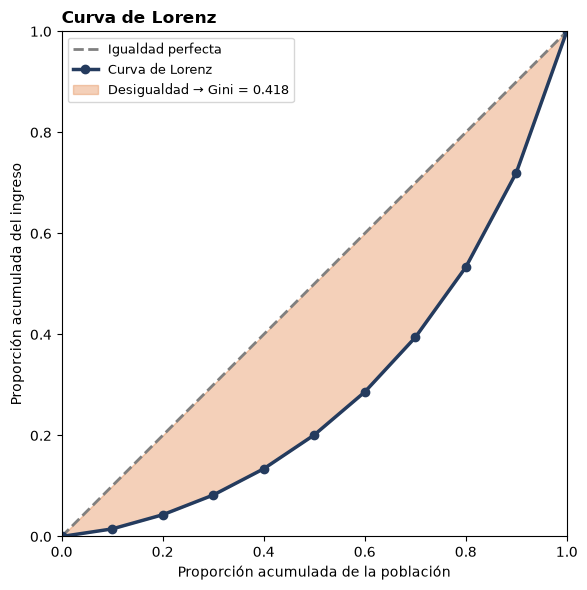

In [30]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.plot([0, 1], [0, 1], "--", color="gray", linewidth=2, label="Igualdad perfecta")
ax.plot(p, L, marker="o", color="#243b5e", linewidth=2.5, label="Curva de Lorenz")
ax.fill_between(p, L, p, color="#e07b39", alpha=0.35, label=f"Desigualdad → Gini = {gini:.3f}")
ax.set_xlabel("Proporción acumulada de la población")
ax.set_ylabel("Proporción acumulada del ingreso")
ax.set_title("Curva de Lorenz", loc="left", fontweight="bold")
ax.legend(loc="upper left", fontsize=9)
ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_aspect("equal")
plt.tight_layout(); plt.show()

El 50 % más pobre se lleva apenas el **20 %** del ingreso, mientras que el 10 % más rico se lleva el **28 %**.

## 5.4 Excedente del consumidor con datos observados

En la Parte 4 calculamos el EC con la fórmula de la demanda. Ahora, como en la vida real, con una tabla:

$$EC = \underbrace{\int_0^{q^*} P(q)\, dq}_{\text{disposición total a pagar}} \; - \; \underbrace{p^* \cdot q^*}_{\text{lo que se pagó}}$$

Disposición total a pagar : $    5,150   ← área bajo la demanda
Lo que realmente pagaron  : $    3,500   ← precio × cantidad
--------------------------------------------
EXCEDENTE DEL CONSUMIDOR  : $    1,650


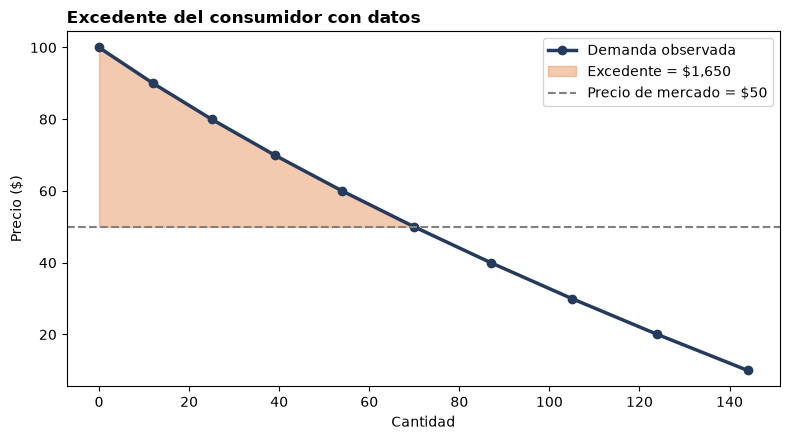

In [31]:
# Estudio de mercado: a cada precio, cuánto se vendería
demanda = pd.DataFrame({
    "precio":   [100, 90, 80, 70, 60, 50, 40, 30, 20, 10],
    "cantidad": [  0, 12, 25, 39, 54, 70, 87, 105, 124, 144],
})

precio_mercado = 50
cantidad_vendida = 70          # a $50 se venden 70 unidades

tramo = demanda[demanda["cantidad"] <= cantidad_vendida].sort_values("cantidad")
disposicion_a_pagar = trapecio(tramo["precio"].values, tramo["cantidad"].values)
gasto_real = precio_mercado * cantidad_vendida
excedente = disposicion_a_pagar - gasto_real

print(f"Disposición total a pagar : $ {disposicion_a_pagar:>8,.0f}   ← área bajo la demanda")
print(f"Lo que realmente pagaron  : $ {gasto_real:>8,.0f}   ← precio × cantidad")
print(f"{'-' * 44}")
print(f"EXCEDENTE DEL CONSUMIDOR  : $ {excedente:>8,.0f}")

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(demanda["cantidad"], demanda["precio"], marker="o", color="#243b5e", linewidth=2.5, label="Demanda observada")
ax.fill_between(tramo["cantidad"], tramo["precio"], precio_mercado, color="#e07b39", alpha=0.4,
                label=f"Excedente = ${excedente:,.0f}")
ax.axhline(precio_mercado, color="gray", linestyle="--", label=f"Precio de mercado = ${precio_mercado}")
ax.set_xlabel("Cantidad"); ax.set_ylabel("Precio ($)"); ax.legend()
ax.set_title("Excedente del consumidor con datos", loc="left", fontweight="bold")
plt.tight_layout(); plt.show()

Calculamos el excedente **sin conocer la fórmula de la demanda**: solo una tabla de 10 filas y la regla del trapecio.

> 🎯 Es lo que hace un regulador cuando evalúa si una fusión de empresas perjudica a los consumidores,
> o una empresa cuando analiza cuánto puede subir un precio.

---
# ⭐ Parte 6 — Ejercicios resueltos
---

Intentá cada ejercicio en la celda *"Tu respuesta acá"*. Las soluciones están en celdas **ocultas**
(en Colab, hacé doble clic sobre la celda de solución o usá *Mostrar código* para ver el código).

## Ejercicio A — Excedente del consumidor con una demanda no lineal

Una plataforma de streaming estimó que la disposición a pagar de sus potenciales suscriptores sigue la
demanda inversa

$$P(q) = 120\, e^{-0{,}02\,q}$$

donde $q$ son miles de suscriptores y $P$ el precio mensual en \$. Hoy cobra **\$30 por mes**.

1. ¿Cuántos suscriptores tiene a ese precio? (resolvé $P(q^*) = 30$)
2. Calculá el **excedente del consumidor** con `sp.integrate` (resultado exacto) y verificalo con `quad`.
3. Graficá la demanda y sombreá el excedente.
4. La empresa evalúa subir el precio a **\$40**. ¿Cuánto excedente pierden los consumidores?
   Verificalo de otra forma: integrando la demanda directa $Q(p)$ entre \$30 y \$40.
5. De esa pérdida, ¿cuánto se transforma en ingreso extra para la empresa (por los que siguen suscriptos)
   y cuánto corresponde a los que se dan de baja?

In [32]:
# Tu respuesta acá

### 🔑 Solución — puntos 1 y 2

Con una demanda curva ya no hay "triángulo": **hace falta la integral**.

$$EC = \int_0^{q^*} \big[P(q) - 30\big]\, dq$$

In [33]:
# @title Solución: cantidad y excedente del consumidor
q, pr = sp.symbols('q p', positive=True)

P = 120 * sp.exp(-sp.Rational(1, 50) * q)      # demanda inversa
p0 = 30

q0 = sp.expand_log(sp.solve(sp.Eq(P, p0), q)[0], force=True)
EC0 = sp.expand_log(sp.simplify(sp.integrate(P - p0, (q, 0, q0))), force=True)

print(f"1) q* = {q0} ≈ {float(q0):.2f} mil suscriptores")
print(f"2) EC (SymPy, exacto) = {EC0} ≈ ${float(EC0):,.2f} mil por mes")

# Verificación numérica con quad
P_num = sp.lambdify(q, P)
area, err = quad(P_num, 0, float(q0))
print(f"   EC (quad)          = ${area - p0 * float(q0):,.2f} mil por mes  (error estimado {err:.1e})")

1) q* = 100*log(2) ≈ 69.31 mil suscriptores
2) EC (SymPy, exacto) = 4500 - 3000*log(2) ≈ $2,420.56 mil por mes
   EC (quad)          = $2,420.56 mil por mes  (error estimado 5.0e-11)


### 🔑 Solución — punto 3

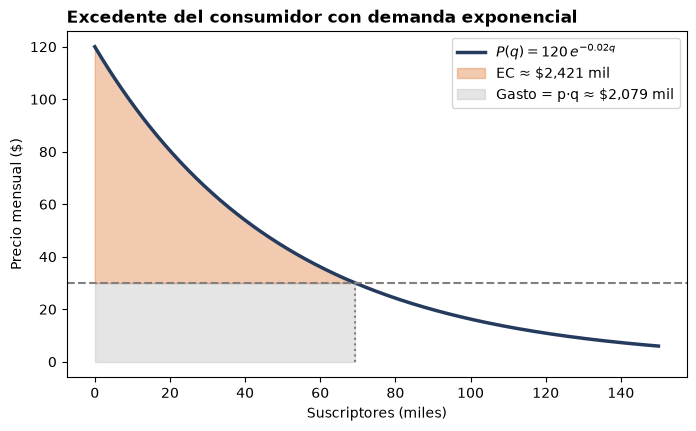

In [34]:
# @title Solución: gráfico del excedente
q_grid = np.linspace(0, 150, 500)
q0f = float(q0)

plt.figure(figsize=(8, 4.5))
plt.plot(q_grid, P_num(q_grid), color="#243b5e", linewidth=2.5, label=r"$P(q)=120\,e^{-0.02q}$")
plt.fill_between(q_grid, P_num(q_grid), p0, where=q_grid <= q0f, color="#e07b39", alpha=0.4,
                 label=f"EC ≈ ${float(EC0):,.0f} mil")
plt.fill_between(q_grid, p0, 0, where=q_grid <= q0f, color="gray", alpha=0.2,
                 label=f"Gasto = p·q ≈ ${p0 * q0f:,.0f} mil")
plt.axhline(p0, color="gray", linestyle="--")
plt.vlines(q0f, 0, p0, color="gray", linestyle=":")
plt.xlabel("Suscriptores (miles)"); plt.ylabel("Precio mensual ($)")
plt.title("Excedente del consumidor con demanda exponencial", loc="left", fontweight="bold")
plt.legend(); plt.show()

### 🔑 Solución — puntos 4 y 5

La pérdida de excedente se puede calcular de dos formas equivalentes:

- **Restando excedentes:** $\Delta EC = EC(30) - EC(40)$.
- **Integrando sobre el precio:** el EC es también el área a la *izquierda* de la demanda, entre el precio
  y el eje vertical. Por eso $\Delta EC = \int_{30}^{40} Q(p)\, dp$, donde $Q(p) = 50\ln\!\left(\frac{120}{p}\right)$ es la demanda directa.

Y la pérdida se descompone en:
- un **rectángulo** $(40 - 30)\cdot q(40)$: lo que pagan de más los que siguen → pasa a la empresa;
- un **área curva** $\int_{q(40)}^{q(30)} [P(q) - 30]\,dq$: el excedente de los que se dan de baja → se pierde.

Suscriptores a $40: 54.93 mil (antes 69.31 mil)
EC a $30 =  2,420.56   EC a $40 =  1,802.78

4) Pérdida de EC (resta de excedentes) = 617.78
   Pérdida de EC (∫ Q(p) dp de 30 a 40) = 617.78   ← coincide

5) Pasa a la empresa (rectángulo)       = 549.31  (89%)
   Se pierde con los que se dan de baja  = 68.48  (11%)


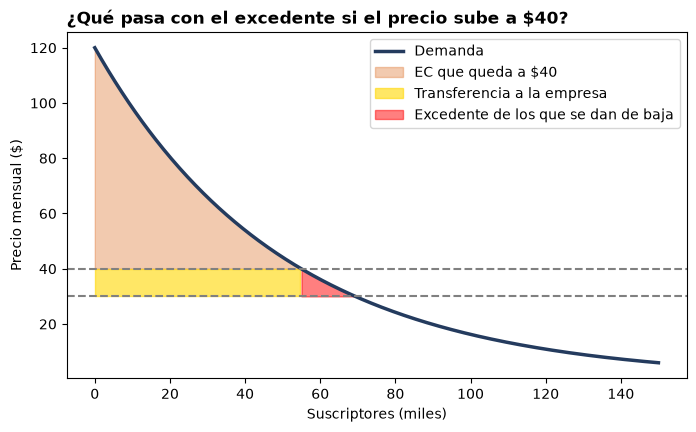

In [35]:
# @title Solución: suba del precio a $40
p1 = 40
q1 = sp.expand_log(sp.solve(sp.Eq(P, p1), q)[0], force=True)
EC1 = sp.expand_log(sp.simplify(sp.integrate(P - p1, (q, 0, q1))), force=True)
perdida = sp.simplify(EC0 - EC1)

# Forma alternativa: integrar la demanda directa Q(p) entre los dos precios
Q = sp.solve(sp.Eq(P, pr), q)[0]
perdida_alt = sp.integrate(Q, (pr, p0, p1))

transferencia = (p1 - p0) * q1
bajas = sp.integrate(P - p0, (q, q1, q0))

print(f"Suscriptores a $40: {float(q1):.2f} mil (antes {float(q0):.2f} mil)")
print(f"EC a $30 = {float(EC0):>9,.2f}   EC a $40 = {float(EC1):>9,.2f}")
print(f"\n4) Pérdida de EC (resta de excedentes) = {float(perdida):,.2f}")
print(f"   Pérdida de EC (∫ Q(p) dp de 30 a 40) = {float(perdida_alt):,.2f}   ← coincide")
print(f"\n5) Pasa a la empresa (rectángulo)       = {float(transferencia):,.2f}  ({float(transferencia / perdida):.0%})")
print(f"   Se pierde con los que se dan de baja  = {float(bajas):,.2f}  ({float(bajas / perdida):.0%})")

q1f = float(q1)
plt.figure(figsize=(8, 4.5))
plt.plot(q_grid, P_num(q_grid), color="#243b5e", linewidth=2.5, label="Demanda")
plt.fill_between(q_grid, P_num(q_grid), p1, where=q_grid <= q1f, color="#e07b39", alpha=0.4, label="EC que queda a $40")
plt.fill_between(q_grid, p1, p0, where=q_grid <= q1f, color="gold", alpha=0.6, label="Transferencia a la empresa")
plt.fill_between(q_grid, P_num(q_grid), p0, where=(q_grid >= q1f) & (q_grid <= q0f), color="red", alpha=0.5,
                 label="Excedente de los que se dan de baja")
plt.axhline(p0, color="gray", linestyle="--"); plt.axhline(p1, color="gray", linestyle="--")
plt.xlabel("Suscriptores (miles)"); plt.ylabel("Precio mensual ($)")
plt.title("¿Qué pasa con el excedente si el precio sube a $40?", loc="left", fontweight="bold")
plt.legend(); plt.show()

**Lectura económica:** la mayor parte de lo que pierden los consumidores no desaparece: se lo queda la
empresa como ingreso. Pero una parte (rojo) se pierde con los suscriptores que se van: es la misma lógica
de la pérdida de peso muerto de la Parte 4.

---

## Ejercicio B — Índice de Gini a partir de curvas de Lorenz

Un estudio estimó las curvas de Lorenz de dos países:

$$\text{País A: } L_A(p) = p^2 \qquad\qquad \text{País B: } L_B(p) = 0{,}3\,p + 0{,}7\,p^4$$

1. Verificá con `SymPy` que ambas son curvas de Lorenz válidas: $L(0)=0$, $L(1)=1$, crecientes ($L' \ge 0$) y convexas ($L'' \ge 0$).
2. Calculá el **coeficiente de Gini** de cada país con `sp.integrate`: $\;G = 1 - 2\int_0^1 L(p)\,dp$.
3. Verificalo con `quad` y con la regla del trapecio usando solo los 11 puntos $p = 0;\ 0{,}1;\ \dots;\ 1$ (como si fueran datos por deciles).
4. ¿Qué porcentaje del ingreso se lleva el 50 % más pobre en cada país? ¿Y el 10 % más rico?
5. Graficá las dos curvas junto con la línea de igualdad. ¿Cuál es más desigual?
6. **Bonus:** demostrá simbólicamente que si $L(p) = p^k$ (con $k \ge 1$), entonces $G = \dfrac{k-1}{k+1}$.

In [36]:
# Tu respuesta acá

### 🔑 Solución — puntos 1 y 2

In [37]:
# @title Solución: validez de las curvas y Gini exacto
p = sp.symbols('p', nonnegative=True)

curvas = {
    "País A": p**2,
    "País B": sp.Rational(3, 10)*p + sp.Rational(7, 10)*p**4,
}

ginis = {}
for pais, Lp in curvas.items():
    d1, d2 = sp.diff(Lp, p), sp.diff(Lp, p, 2)
    print(f"{pais}: L(p) = {Lp}")
    print(f"   L(0) = {Lp.subs(p, 0)},  L(1) = {Lp.subs(p, 1)},  L'(p) = {d1},  L''(p) = {d2}")

    area = sp.integrate(Lp, (p, 0, 1))
    ginis[pais] = 1 - 2*area
    print(f"   ∫ L(p) dp = {area}   →   Gini = {ginis[pais]} ≈ {float(ginis[pais]):.4f}\n")

País A: L(p) = p**2
   L(0) = 0,  L(1) = 1,  L'(p) = 2*p,  L''(p) = 2
   ∫ L(p) dp = 1/3   →   Gini = 1/3 ≈ 0.3333

País B: L(p) = 7*p**4/10 + 3*p/10
   L(0) = 0,  L(1) = 1,  L'(p) = 14*p**3/5 + 3/10,  L''(p) = 42*p**2/5
   ∫ L(p) dp = 29/100   →   Gini = 21/50 ≈ 0.4200



Ambas cumplen las cuatro condiciones (en $[0,1]$ las derivadas son no negativas). El país B tiene un Gini
de **0,42**, parecido al de Argentina; el país A, **0,33**, más cercano a Europa continental.

### 🔑 Solución — puntos 3 y 4

In [38]:
# @title Solución: verificación numérica y participación por grupos
p_deciles = np.linspace(0, 1, 11)

filas = []
for pais, Lp in curvas.items():
    L_num = sp.lambdify(p, Lp)
    area_quad, _ = quad(L_num, 0, 1)
    area_trap = trapecio(L_num(p_deciles), p_deciles)
    filas.append({
        "País": pais,
        "Gini exacto": float(ginis[pais]),
        "Gini quad": 1 - 2*area_quad,
        "Gini trapecio (deciles)": 1 - 2*area_trap,
        "50% más pobre (% ingreso)": 100 * float(Lp.subs(p, sp.Rational(1, 2))),
        "10% más rico (% ingreso)": 100 * (1 - float(Lp.subs(p, sp.Rational(9, 10)))),
    })

with pd.option_context("display.float_format", "{:.4f}".format):
    display(pd.DataFrame(filas).set_index("País"))

,Gini exacto,Gini quad,Gini trapecio (deciles),50% más pobre (% ingreso),10% más rico (% ingreso)
País,,,,,
País A,0.3333,0.3333,0.3300,25.0000,19.0000
País B,0.4200,0.4200,0.4153,19.3750,27.0730


- `quad` coincide con el valor exacto; el **trapecio con deciles subestima levemente el Gini**: como la curva
  es convexa, las rectas pasan *por encima* de ella y agrandan el área bajo la Lorenz.
- En el país A el 50 % más pobre se lleva el **25 %** del ingreso; en el B, apenas el **19,4 %**.
  El 10 % más rico se lleva el **19 %** en A y el **27,1 %** en B.

### 🔑 Solución — puntos 5 y 6

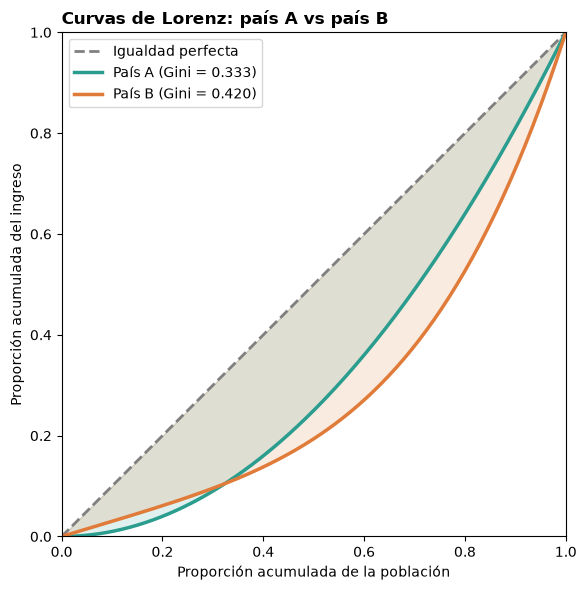

Gini para L(p) = p^k : (k - 1)/(k + 1)
Con k = 2 (país A)   : 1/3


In [39]:
# @title Solución: gráfico y fórmula general
p_grid = np.linspace(0, 1, 200)

fig, ax = plt.subplots(figsize=(6, 6))
ax.plot([0, 1], [0, 1], "--", color="gray", linewidth=2, label="Igualdad perfecta")
for (pais, Lp), color in zip(curvas.items(), ["#2a9d8f", "#e07b39"]):
    L_vals = sp.lambdify(p, Lp)(p_grid)
    ax.plot(p_grid, L_vals, color=color, linewidth=2.5, label=f"{pais} (Gini = {float(ginis[pais]):.3f})")
    ax.fill_between(p_grid, L_vals, p_grid, color=color, alpha=0.15)
ax.set_xlabel("Proporción acumulada de la población")
ax.set_ylabel("Proporción acumulada del ingreso")
ax.set_title("Curvas de Lorenz: país A vs país B", loc="left", fontweight="bold")
ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_aspect("equal"); ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

# Bonus: fórmula general para L(p) = p^k
k = sp.symbols('k', positive=True)
G_k = sp.simplify(1 - 2*sp.integrate(p**k, (p, 0, 1)))
print("Gini para L(p) = p^k :", G_k)
print("Con k = 2 (país A)   :", G_k.subs(k, 2))

**Conclusión:** la curva del país B está siempre por debajo de la del A, así que B es **más desigual**
en todos los tramos de la distribución, no solo en promedio. Y el Gini lo resume en un solo número:
es **una integral**, el área entre la diagonal y la curva.

---
# 📝 Parte 7 — Ejercicios para practicar
---

**Ejercicio 1 (de marginal a total).** Una empresa tiene ingreso marginal $IMg(q) = 50 - 0{,}5q$,
costo marginal $CMg(q) = 10 + 0{,}3q$ y un costo fijo de \$100.

1. Recuperá $I(q)$ integrando (con $I(0) = 0$).
2. Recuperá $C(q)$ integrando y usando el costo fijo para la constante.
3. Obtené $B(q) = I(q) - C(q)$.
4. Encontrá $q^*$ con $IMg = CMg$ y calculá el beneficio máximo $B(q^*)$.
5. Graficá $I$, $C$ y $B$ en el mismo gráfico.

In [40]:
# Tu respuesta acá

**Ejercicio 2 (impuestos).** En el mercado de la Parte 4 ($Q_d = 120 - 3p$, $Q_s = -20 + 2p$), el gobierno
duplica el impuesto a **\$10 por unidad**. Calculá con integrales el nuevo EC, EP, la recaudación y la
pérdida de peso muerto. ¿La DWL se duplicó, o creció más? ¿Por qué?

In [41]:
# Tu respuesta acá

**Ejercicio 3 (excedente con datos).** En el caso de la Parte 5.4, ¿qué pasa si el precio de mercado baja a
\$40? Recalculá el excedente del consumidor. ¿Aumentó o disminuyó? ¿Por qué tiene sentido económico?

In [42]:
# Tu respuesta acá

**Ejercicio 4 (Gini con datos).** Calculá el Gini de una distribución **más igualitaria**:
`[4.0, 5.5, 6.8, 8.0, 9.2, 10.5, 12.0, 13.5, 15.0, 15.5]`. Graficá su curva de Lorenz junto con la de la
Parte 5.3 y compará.

In [43]:
# Tu respuesta acá

**Ejercicio 5 (inflación).** La inflación mensual de un semestre fue: 4,2 · 3,8 · 5,1 · 4,6 · 3,9 · 4,4 (en %).
Calculá la inflación acumulada del semestre. ¿Cuánto da si la sumás mal? ¿Cuántos puntos de diferencia hay?

In [44]:
# Tu respuesta acá

**Ejercicio 6 (¿suma o integral?).** Una fábrica mide su ritmo de producción (unidades por hora) cada 2 horas
durante una jornada de 8 horas: `[120, 145, 160, 155, 130]` a las horas `[0, 2, 4, 6, 8]`.
¿Cuántas unidades produjo en total? **Pensá bien:** ¿esto se suma o se integra?

In [45]:
# Tu respuesta acá

---
## 🧭 Para llevarse

| Situación | Herramienta |
|---|---|
| Tengo la **fórmula** y quiero el resultado exacto | `sp.integrate(f, x)` o `sp.integrate(f, (x, a, b))` |
| Tengo la **fórmula** y me alcanza un número | `quad(f, a, b)` |
| Tengo **datos** de una velocidad o tasa | `trapecio(y, x)` o `simpson(y, x=x)` |
| Tengo **datos** de totales ya cerrados | `.sum()` |
| Quiero la evolución acumulada | `.cumsum()` (sumas) o `.cumprod()` (tasas) |

| Concepto económico | Integral |
|---|---|
| Costo total desde el marginal | $C(q) = \int CMg\,dq + CF$ |
| Acumulado entre dos niveles | $\int_a^b \text{Marginal}(q)\,dq$ |
| Excedente del consumidor | $\int_0^{q^*} [P_d(q) - p^*]\,dq$ |
| Excedente del productor | $\int_0^{q^*} [p^* - P_s(q)]\,dq$ |
| Pérdida de peso muerto | $\int_{q^t}^{q^*} [P_d(q) - P_s(q)]\,dq$ |
| Coeficiente de Gini | $1 - 2\int_0^1 L(p)\,dp$ |

**Las tres frases para llevarse:**
1. Una integral definida **siempre** es un área bajo una curva.
2. Sin fórmula igual se integra: la regla del trapecio alcanza para decidir.
3. Antes de sumar, preguntate si el dato es un **total cerrado** o una **velocidad**.